# 🎤 Opinión y discurso de odio en los comentarios de YouTube con R

Esta notebook es la versión en R de la [notebook de Python](https://colab.research.google.com/drive/1TIFVmF9gu1nDIfZrv3LBOBp_pYJ3Sux4): trae los comentarios de un video de YouTube con su API, clasifica su sentimiento y detecta discurso de odio. Hace exactamente lo mismo, así que sirve para comparar los dos lenguajes. Los pasos donde R tiene alguna limitación están marcados con ⚠️.

El video elegido es la sesión de **Residente con Bizarrap** (BZRP Music Sessions #49), de marzo de 2022: una *tiraera* contra J Balvin con más de 200 millones de reproducciones y más de 340 mil comentarios. Es un buen caso para analizar opinión: hay fanatismo, burla, defensa y también agresión.

<a href="https://www.youtube.com/watch?v=HO73gUhiYe0" target="_blank"><img src="https://img.youtube.com/vi/HO73gUhiYe0/maxresdefault.jpg" alt="Residente || BZRP Music Sessions #49" width="560"></a>

*Al hacer clic en la imagen, el video se abre en YouTube.*

Los pasos son cinco:

1. Traer los datos del video y sus comentarios con la API de YouTube Data v3.
2. Limpiar el texto de los comentarios.
3. Clasificar el sentimiento de cada comentario: positivo, negativo o neutro.
4. Detectar discurso de odio.
5. Analizar los resultados y guardarlos.

> La notebook usa el entorno de R de Colab con GPU: en el menú **Entorno de ejecución > Cambiar tipo de entorno de ejecución**, elegir **R** y **T4 GPU**. Sin GPU también funciona, pero los modelos tardan varios minutos.

## 📦 Los paquetes

Algunos de los paquetes que usamos no vienen instalados en el entorno de R de Colab.

> ⚠️ **Limitación de R.** En Linux, R instala los paquetes desde el código fuente y los tiene que compilar: con `arrow`, eso tarda varios minutos. En Python, `pip` baja los paquetes ya compilados. Para acelerar, usamos el repositorio de Posit, que tiene los paquetes de R compilados para Linux, y así la instalación tarda segundos.

In [ ]:
# Repositorio de Posit con los paquetes ya compilados para la versión de Linux de Colab
ubuntu <- system("lsb_release -cs", intern = TRUE)
options(repos = c(CRAN = paste0("https://packagemanager.posit.co/cran/__linux__/", ubuntu, "/latest")))
# El repositorio reconoce la versión de R por esta "firma" de los pedidos
options(HTTPUserAgent = sprintf("R/%s R (%s)", getRversion(), paste(getRversion(), R.version["platform"], R.version["arch"], R.version["os"])))

install.packages(c("tidytext", "stopwords", "wordcloud", "arrow", "reticulate"))

# reticulate tiene que usar el Python de Colab, que ya tiene instalados torch y transformers
Sys.setenv(RETICULATE_PYTHON = "/usr/bin/python3")

library(httr2)
library(dplyr)
library(stringr)
library(ggplot2)
library(tidytext)
library(wordcloud)
library(arrow)
library(reticulate)

options(repr.plot.width = 10, repr.plot.height = 4)   # gráficos más anchos en Colab

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘SnowballC’, ‘janeaustenr’, ‘tokenizers’, ‘ISOcodes’, ‘assertthat’, ‘RcppTOML’, ‘here’, ‘png’



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union


Loading required package: RColorBrewer


Attaching package: ‘arrow’


The following object is masked from ‘package:utils’:

    timestamp




## 🔑 La clave de la API

La API de YouTube pide una **clave** (API key), que se obtiene gratis en Google Cloud:

1. Entrar a https://console.cloud.google.com y crear un proyecto.
2. En **APIs y servicios > Biblioteca**, buscar **YouTube Data API v3** y habilitarla.
3. En **APIs y servicios > Credenciales**, hacer clic en **Crear credenciales > Clave de API**, restringirla a YouTube Data API v3 y copiar la clave.

> ⚠️ **Limitación de R.** En Python guardamos la clave como **secreto** de Colab, para que no quede escrita en la notebook. Desde R no se pueden leer esos secretos: Colab solo los ofrece a Python. Por eso acá la clave se escribe en el código, y **hay que borrarla antes de compartir la notebook**.

In [ ]:
API_KEY <- "PEGAR_ACA_LA_CLAVE"

API <- "https://www.googleapis.com/youtube/v3"

## 🎬 El video

Cada video tiene un identificador: es lo que aparece después de `v=` en su dirección. Para analizar otro video, alcanza con cambiar `VIDEO_ID`.

El endpoint `videos` devuelve los datos del video y sus estadísticas.

> ⚠️ **Limitación de R.** Google no tiene una biblioteca oficial de sus APIs para R, como la que usamos en Python. Armamos los pedidos con `httr2`, como en las notebooks de la unidad, y la clave viaja en cada pedido.

In [ ]:
VIDEO_ID <- "HO73gUhiYe0"   # https://www.youtube.com/watch?v=HO73gUhiYe0

respuesta <- request(API) |>
  req_url_path_append("videos") |>
  req_url_query(part = "snippet,statistics", id = VIDEO_ID, key = API_KEY) |>
  req_perform() |>
  resp_body_json()

video <- respuesta$items[[1]]

cat("Título:", video$snippet$title, "\n")
cat("Canal:", video$snippet$channelTitle, "\n")
cat("Publicado:", substr(video$snippet$publishedAt, 1, 10), "\n")
cat("Vistas:", video$statistics$viewCount, "\n")
cat("Me gusta:", video$statistics$likeCount, "\n")
cat("Comentarios:", video$statistics$commentCount, "\n")

Título: RESIDENTE || BZRP Music Sessions #49/66 
Canal: Bizarrap 
Publicado: 2022-03-03 
Vistas: 213955562 
Me gusta: 6581711 
Comentarios: 343241 


## 💬 Los comentarios

El endpoint `commentThreads` devuelve los comentarios principales del video, de a 100 por pedido. Pedimos los más relevantes, en el mismo orden en que los muestra YouTube, y repetimos el pedido hasta juntar `CANTIDAD` comentarios. Cada respuesta trae un `nextPageToken`, que se manda en el pedido siguiente para recibir la página que sigue; cuando no viene, no hay más comentarios.

Cada pedido consume 1 unidad de la cuota diaria de la API, que es de 10.000 unidades: traer 1.000 comentarios cuesta 10.

De cada comentario guardamos su identificador, el texto, los "Me gusta", la cantidad de respuestas y la fecha. No guardamos el nombre de quien comenta: para analizar la opinión no hace falta.

Por las dudas, al final usamos el identificador como clave para quedarnos con los comentarios distintos, como con la clave primaria de una tabla. En la notebook de Python se cuenta por qué.

In [ ]:
CANTIDAD <- 1000

comentarios <- list()
token <- NULL

repeat {
  respuesta <- request(API) |>
    req_url_path_append("commentThreads") |>
    req_url_query(part = "snippet", videoId = VIDEO_ID, maxResults = 100,
                  order = "relevance", textFormat = "plainText",
                  pageToken = token, key = API_KEY) |>
    req_perform() |>
    resp_body_json()

  for (item in respuesta$items) {
    datos <- item$snippet$topLevelComment$snippet
    comentarios[[length(comentarios) + 1]] <- data.frame(
      id = item$id,
      comentario = datos$textDisplay,
      likes = datos$likeCount,
      respuestas = item$snippet$totalReplyCount,
      fecha = datos$publishedAt
    )
  }

  token <- respuesta$nextPageToken   # NULL si no hay más páginas
  if (is.null(token) || length(comentarios) >= CANTIDAD) break
}

df <- bind_rows(comentarios)
cat("Comentarios descargados:", nrow(df), "\n")

df <- distinct(df, id, .keep_all = TRUE)
cat("Comentarios distintos:", nrow(df), "\n")

df$fecha <- as.POSIXct(df$fecha, format = "%Y-%m-%dT%H:%M:%SZ", tz = "UTC")

Comentarios descargados: 1000 
Comentarios distintos: 1000 


In [ ]:
head(df, 10)

,id,comentario,likes,respuestas,fecha
,<chr>,<chr>,<int>,<int>,<dttm>
1,UgzNYGI2ePs95hU9pyF4AaABAg,Hasta mi hermano Don sabe que en el rap hay un solo King Kong,224978,689,2022-03-04 14:31:21
2,UgxL17Cs2Y0bJ_ppr1d4AaABAg,YO SOLO VOLVÍ AQUI PARA RECORDAR EL HATE DE JBALVIN AHORA QUE RECIÉN SE SEPARA DE VALENTINA,544,5,2026-09-17 02:04:42
3,Ugy16Bxb6UX_jgOY-zh4AaABAg,"Me acuerdo cuando residente cancelaron su concierto en Perú, el tipo fue a la plaza san martin de lima, hizo un show abierto a todo el publico cantando gratis, a pesar que los serenazgos lo querian sacar el tipo siguio cantando",2482,11,2022-03-19 03:46:56
4,UgyyX1JtPQCW3G4gP_Z4AaABAg,"Vine aquí después de que el Bobolon le puso cuernos a su Esposa. ""Se tiene que tatuar la palabra lealtad porque se le olvida""",280,0,2026-09-17 21:56:55
5,Ugzqu5RsVjk3-q5YwWR4AaABAg,Esta canción dura casi 9 minutos y se siente como de 3 minutos.,410,5,2022-03-26 17:26:11
6,UgwWoA4fcKXrw04lwmF4AaABAg,"""Mis Billboard los sostiene la gente junto a mis letras en cada pancarta pa bajar a un presidente"" cuanta verdad 🛐🛐🛐",365,3,2022-03-04 14:45:54
7,UgyzyskK4HliEcrdtPF4AaABAg,"“Mis billboards, los sostiene la gente junto a mis letras en cada pancarta pa' bajar un presidente” tremenda frase",1662,4,2022-03-04 22:13:52
8,UgzOcPGSQl2IskzdETx4AaABAg,quien regresó después de la funa por la separación de Valentina Ferrer??? Residente siempre tuvo la razón,1248,30,2026-09-17 19:07:40
9,Ugzl7ZjmxjHam-rlGvZ4AaABAg,“Son artistas de quinta que escriben menos que un bolígrafo sin tinta” 💪🏻🔥🔥🔥🔥,231,1,2022-03-04 18:41:13


## 🧹 Limpieza del texto

Como en la notebook de sentimiento, pasamos los emojis a texto (😂 se convierte en `:cara_llorando_de_risa:`), llevamos todo a minúsculas y sacamos los enlaces. Los emojis no se borran porque aportan información: aprobación, burla o enojo.

> ⚠️ **Limitación de R.** Los paquetes de R que traducen emojis los pasan a nombres en inglés. Para tener los mismos nombres en español que en Python, usamos el paquete `emoji` de Python a través de `reticulate`, un paquete de R que permite usar bibliotecas de Python desde R.

In [ ]:
system("pip install emoji -q")   # instala el paquete de Python
emoji <- import("emoji")

limpiar <- function(texto) {
  texto <- emoji$demojize(texto, language = "es")
  texto <- tolower(texto)
  texto <- str_replace_all(texto, "http\\S+|www\\.\\S+", " ")   # enlaces
  texto <- str_squish(texto)                                       # espacios de más
  texto
}

df$comentario_limpio <- sapply(df$comentario, limpiar, USE.NAMES = FALSE)
df <- filter(df, comentario_limpio != "")

head(select(df, comentario, comentario_limpio))

,comentario,comentario_limpio
,<chr>,<chr>
1,Hasta mi hermano Don sabe que en el rap hay un solo King Kong,hasta mi hermano don sabe que en el rap hay un solo king kong
2,YO SOLO VOLVÍ AQUI PARA RECORDAR EL HATE DE JBALVIN AHORA QUE RECIÉN SE SEPARA DE VALENTINA,yo solo volví aqui para recordar el hate de jbalvin ahora que recién se separa de valentina
3,"Me acuerdo cuando residente cancelaron su concierto en Perú, el tipo fue a la plaza san martin de lima, hizo un show abierto a todo el publico cantando gratis, a pesar que los serenazgos lo querian sacar el tipo siguio cantando","me acuerdo cuando residente cancelaron su concierto en perú, el tipo fue a la plaza san martin de lima, hizo un show abierto a todo el publico cantando gratis, a pesar que los serenazgos lo querian sacar el tipo siguio cantando"
4,"Vine aquí después de que el Bobolon le puso cuernos a su Esposa. ""Se tiene que tatuar la palabra lealtad porque se le olvida""","vine aquí después de que el bobolon le puso cuernos a su esposa. ""se tiene que tatuar la palabra lealtad porque se le olvida"""
5,Esta canción dura casi 9 minutos y se siente como de 3 minutos.,esta canción dura casi 9 minutos y se siente como de 3 minutos.
6,"""Mis Billboard los sostiene la gente junto a mis letras en cada pancarta pa bajar a un presidente"" cuanta verdad 🛐🛐🛐","""mis billboard los sostiene la gente junto a mis letras en cada pancarta pa bajar a un presidente"" cuanta verdad :lugar_de_culto::lugar_de_culto::lugar_de_culto:"


## 🙂 Sentimiento

Usamos el mismo modelo que en la notebook de sentimiento, `cardiffnlp/twitter-xlm-roberta-base-sentiment`: un modelo multilingüe entrenado con tuits, así que entiende el lenguaje informal y también los comentarios en inglés o portugués. Para cada comentario devuelve una etiqueta (negativo, neutro o positivo) y un puntaje entre 0 y 1, que indica qué tan seguro está.

> ⚠️ **Limitación de R.** Los modelos de Hugging Face están hechos para usarse desde Python, con la biblioteca `transformers`, y R no tiene una forma propia de correrlos. Con `reticulate` llamamos a `transformers` desde R: funciona, pero en el fondo corre Python, y si algo falla, el error llega con un mensaje de Python.

Primero lo probamos con una frase.

In [ ]:
transformers <- import("transformers")
torch <- import("torch")

dispositivo <- if (torch$cuda$is_available()) 0L else -1L   # 0 = GPU, -1 = CPU

modelo_sentimiento <- transformers$pipeline(
  "text-classification",
  model = "cardiffnlp/twitter-xlm-roberta-base-sentiment",
  device = dispositivo
)

modelo_sentimiento("qué temazo, rené la rompió toda")

[[1]]
[[1]]$label
[1] "positive"

[[1]]$score
[1] 0.8802851

Ahora clasificamos todos los comentarios. El modelo los procesa de a grupos de 32 (`batch_size`) y corta los comentarios muy largos (`truncation`). Los números van con `L` (`32L`) porque Python espera enteros, y en R un número sin `L` es decimal; `as.list()` convierte el vector de R en una lista de Python.

In [ ]:
ETIQUETAS <- c(negative = "NEG", neutral = "NEU", positive = "POS")

resultados <- modelo_sentimiento(as.list(df$comentario_limpio), batch_size = 32L, truncation = TRUE, max_length = 256L)

etiquetas <- c()
puntajes <- c()
for (r in resultados) {
  etiquetas <- c(etiquetas, ETIQUETAS[[r$label]])
  puntajes <- c(puntajes, round(r$score, 3))
}

df$sentimiento <- etiquetas
df$sentimiento_score <- puntajes

count(df, sentimiento)

sentimiento,n
<chr>,<int>
NEG,296
NEU,322
POS,382


## 🤬 Discurso de odio

Como en la notebook de discurso de odio, usamos `Hate-speech-CNERG/dehatebert-mono-spanish`, entrenado para detectar discurso de odio en español. Clasifica cada comentario como `HATE` (odio, insulto o agresión explícita) o `NON_HATE`. Como solo conoce el español, los comentarios en otros idiomas pueden quedar mal clasificados.

In [ ]:
modelo_odio <- transformers$pipeline(
  "text-classification",
  model = "Hate-speech-CNERG/dehatebert-mono-spanish",
  device = dispositivo
)

resultados <- modelo_odio(as.list(df$comentario_limpio), batch_size = 32L, truncation = TRUE, max_length = 256L)

etiquetas <- c()
puntajes <- c()
for (r in resultados) {
  etiquetas <- c(etiquetas, r$label)
  puntajes <- c(puntajes, round(r$score, 3))
}

df$odio <- etiquetas
df$odio_score <- puntajes

count(df, odio)

odio,n
<chr>,<int>
HATE,33
NON_HATE,967


## 📊 ¿Qué dicen los comentarios?

Empezamos por la distribución de las dos clasificaciones.

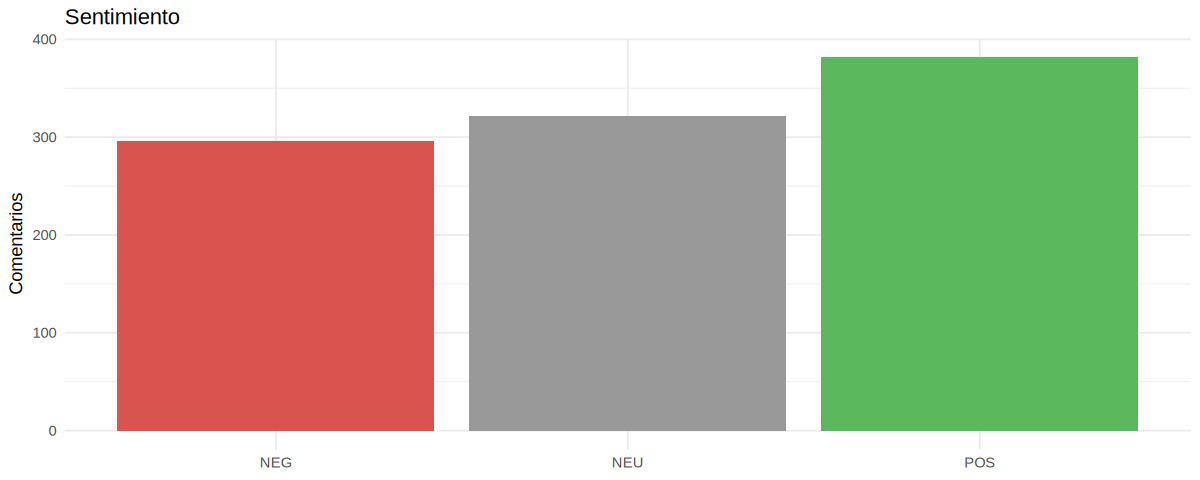

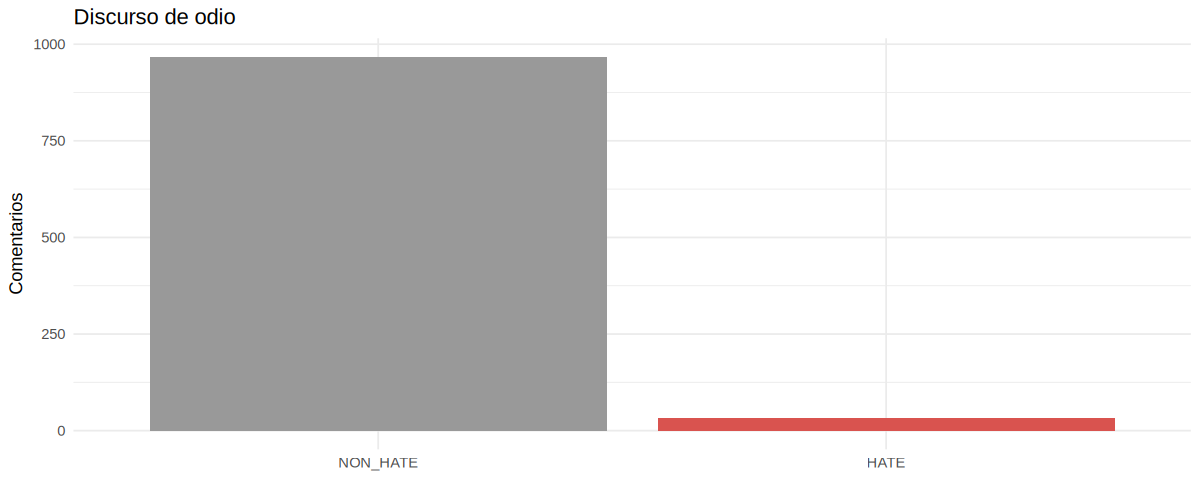

In [ ]:
grafico_sentimiento <- ggplot(df, aes(x = factor(sentimiento, levels = c("NEG", "NEU", "POS")), fill = sentimiento)) +
  geom_bar() +
  scale_fill_manual(values = c(NEG = "#d9534f", NEU = "#999999", POS = "#5cb85c")) +
  labs(title = "Sentimiento", x = NULL, y = "Comentarios") +
  theme_minimal() +
  theme(legend.position = "none")

grafico_odio <- ggplot(df, aes(x = factor(odio, levels = c("NON_HATE", "HATE")), fill = odio)) +
  geom_bar() +
  scale_fill_manual(values = c(NON_HATE = "#999999", HATE = "#d9534f")) +
  labs(title = "Discurso de odio", x = NULL, y = "Comentarios") +
  theme_minimal() +
  theme(legend.position = "none")

print(grafico_sentimiento)
print(grafico_odio)

In [ ]:
# Porcentaje de cada sentimiento
round(prop.table(table(df$sentimiento)) * 100, 1)


 NEG  NEU  POS 
29.6 32.2 38.2 

### 👍 Los comentarios con más apoyo

Los "Me gusta" indican qué opiniones encuentran eco en la comunidad. Vemos los diez comentarios con más likes y cómo los clasificaron los modelos.

In [ ]:
df |>
  arrange(desc(likes)) |>
  select(comentario, likes, sentimiento, odio) |>
  head(10)

,comentario,likes,sentimiento,odio
,<chr>,<int>,<chr>,<chr>
1,Hasta mi hermano Don sabe que en el rap hay un solo King Kong,224978,NEU,NON_HATE
2,"""esto es por los pibes... por el respeto que merece todo aquel que escribe"" La rompiste toda.",9602,POS,NON_HATE
3,"Vaya Temazo René y El Bizzarap La mrd siempre sale a flote, gran frase",5758,POS,NON_HATE
4,Llegaron los duros 💪 temazo!,5717,POS,NON_HATE
5,100 millones 😎🔥,5100,NEG,NON_HATE
6,"""una cosa es ser artista, otra ser famoso"" ESTA PARTE SE GRITA",4972,NEU,NON_HATE
7,Todos viendo una tiradera por primera vez con 53 millones de vistas sin ser un hit para bailar y siendo 2 en tendencia mundial..... 2 minutos para un hit .. pero residente 8 minutos y si les tumbó el marketing residente... De un tirón... 💯🔥,4628,NEG,NON_HATE
8,Este no es home run es un GRAAAAAAND SLAAAAAAM,3833,POS,NON_HATE
9,La sesión de Daddy me trajo de vuelta acá🤭🫡,2977,NEU,NON_HATE


### 🔥 El odio que recibe apoyo

Los comentarios clasificados como odio con más "Me gusta" muestran qué formas de agresión logran resonancia. Conviene leerlos con atención: el modelo también se equivoca.

In [ ]:
df |>
  filter(odio == "HATE") |>
  arrange(desc(likes)) |>
  select(comentario, likes, sentimiento, odio_score) |>
  head(10)

,comentario,likes,sentimiento,odio_score
,<chr>,<int>,<chr>,<dbl>
1,Es increíble que en 11 días tenga 64 millones una barbaridad que grande biza representante de Argentina,708,NEG,0.902
2,Que locura que ya hace tres años desde que salio esta tiradera magnifica de Rene. Increible como pasa el tiempo. Guao.,686,POS,0.661
3,"Uffff esta tremendo, RESIDENTE siendo RESIDENTE el puto amo ... todo un crack",386,POS,0.732
4,"Solo hablo de música, está es la mejor de bizzarap,este loco dejo la vara muy alta.",253,POS,0.656
5,UFFFFFFFFFFFFF SIN PALABRAAAAAAS! Increíble la lírica cruda y pura de Residente. Muy parado <3,207,NEG,0.574
6,Que hubiera sido un Bizza x Cancerbero,56,NEG,0.619
7,Alguien mas vino después de funar a Balvin? Residente yo SIEMPRE te creí,28,NEU,0.529
8,Residente siempre tuvo razón 🔥 tiró puros factos de balvin,7,NEU,0.777
9,Que nivel de barrida le dio a balvin,5,NEG,0.829


### 🔄 Sentimiento y odio

El odio no siempre coincide con el sentimiento negativo: también aparece en burlas o en comentarios irónicos. Una tabla cruzada muestra cómo se combinan las dos clasificaciones.

In [ ]:
table(sentimiento = df$sentimiento, odio = df$odio)

           odio
sentimiento HATE NON_HATE
        NEG    9      287
        NEU    8      314
        POS   16      366

### 🎯 ¿Qué se dice de J Balvin?

La canción es una respuesta a J Balvin, así que muchos comentarios hablan de él. Con `str_detect()` marcamos los comentarios que lo mencionan y comparamos su sentimiento con el del resto (`margin = 1` muestra la proporción de cada fila).

In [ ]:
df$menciona_balvin <- str_detect(df$comentario_limpio, "balvin")

cat("Comentarios que mencionan a Balvin:", sum(df$menciona_balvin), "\n")

round(prop.table(table(menciona_balvin = df$menciona_balvin, sentimiento = df$sentimiento), margin = 1), 2)

Comentarios que mencionan a Balvin: 71 


               sentimiento
menciona_balvin  NEG  NEU  POS
          FALSE 0.28 0.32 0.40
          TRUE  0.56 0.31 0.13

In [ ]:
round(prop.table(table(menciona_balvin = df$menciona_balvin, odio = df$odio), margin = 1), 2)

               odio
menciona_balvin HATE NON_HATE
          FALSE 0.03     0.97
          TRUE  0.10     0.90

In [ ]:
df |>
  filter(menciona_balvin) |>
  arrange(desc(likes)) |>
  select(comentario, likes, sentimiento, odio) |>
  head(10)

,comentario,likes,sentimiento,odio
,<chr>,<int>,<chr>,<chr>
1,"51.74 millones de vistas y siendo casi 9 minutos de canción!!! wooow ojalá tome un nuevo rumbo la música tras superar esta pandemia... yo diría; ""gracias Balvin"" por destapar la botella para que mi paladar saboree el elixir de la felicidad al darle en la jeta a tanto becerro con delirio de grandeza y cero destreza.",590,POS,NON_HATE
2,YO SOLO VOLVÍ AQUI PARA RECORDAR EL HATE DE JBALVIN AHORA QUE RECIÉN SE SEPARA DE VALENTINA,544,NEG,NON_HATE
3,Aquí después de Balvin?🤣🤣,426,NEU,NON_HATE
4,"ahora estendemos lo de J balvin relacionando a Diddy "" por cada mamada subía un escalon"" 👀",314,NEU,NON_HATE
5,Una bestialidad mi respeto residente. - R.I.P bobo balvin,235,NEG,NON_HATE
6,4:58 ahora ya sabemos por que J Balvin no colaborará con el biza jajaxd,224,NEU,NON_HATE
7,"A noche cuando lo ví por primera vez tenía 2M de views, y ahora en menos de 24hs tiene 23M de views. Y hay gente que dice que René no pega temas jajaja. Que los escritores de J Balvin tomen nota como se hace.",216,NEU,NON_HATE
8,quien aqui despues de que anunciaron la session de j balvin,213,NEU,NON_HATE
9,"🤜🏼🤛🏽🔥🔥🔥🔥 J Balvin como otros artistas de acá de Colombia dieron la espalda en las marchas, personas que perdieron sus ojos, perdieron su vida, perdieron a hijos, herman@s, padres. Y nadie (Artistas) dijo NADA!!! 😞",201,NEG,NON_HATE


### 🧬 Las expresiones más repetidas

Contamos los pares de palabras (*bigramas*) más frecuentes en los comentarios negativos, sin las palabras vacías del español (de, la, que...) ni los emojis, que suelen repetirse en cadena (🔥🔥🔥) y taparían a las palabras. Con `tidytext`, primero separamos cada comentario en palabras y sacamos las vacías, y después armamos los pares.

In [ ]:
stopwords_es <- stopwords::stopwords("es")

sacar_emojis <- function(texto) {
  str_replace_all(texto, ":[^:\\s]+:", " ")   # los emojis convertidos a texto, como :fuego:
}

expresiones_frecuentes <- function(textos, n = 15) {
  palabras <- tibble(id = seq_along(textos), texto = sacar_emojis(textos)) |>
    unnest_tokens(palabra, texto) |>
    filter(!palabra %in% stopwords_es, nchar(palabra) > 1)

  palabras |>
    group_by(id) |>
    summarise(texto = paste(palabra, collapse = " ")) |>
    unnest_tokens(expresion, texto, token = "ngrams", n = 2) |>
    filter(!is.na(expresion)) |>
    count(expresion, name = "frecuencia", sort = TRUE) |>
    head(n)
}

expresiones_frecuentes(df$comentario_limpio[df$sentimiento == "NEG"])

expresion,frecuencia
<chr>,<int>
palabra lealtad,9
tatuar palabra,8
lealtad olvida,7
rapero favorito,4
sigue muerto,4
2026 todavía,3
balvin sigue,3
después ver,3
hace años,3


### ☁️ Nubes de palabras

Una nube de palabras muestra las palabras más frecuentes de un conjunto de textos: cuanto más grande, más veces aparece. Armamos una con los comentarios positivos y otra con los negativos, sin las palabras vacías del español y del inglés ni los emojis. Al comparar las dos nubes, conviene preguntarse si las palabras de la negativa expresan críticas o si vienen de frases de la canción que la gente cita.

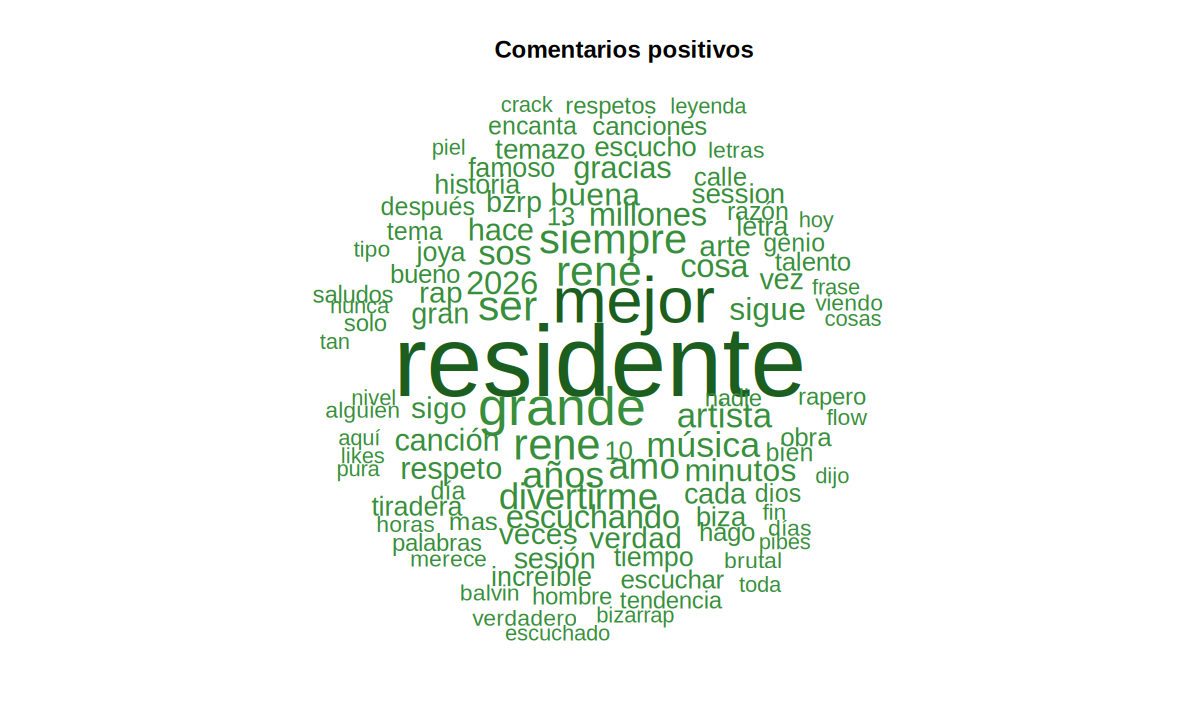

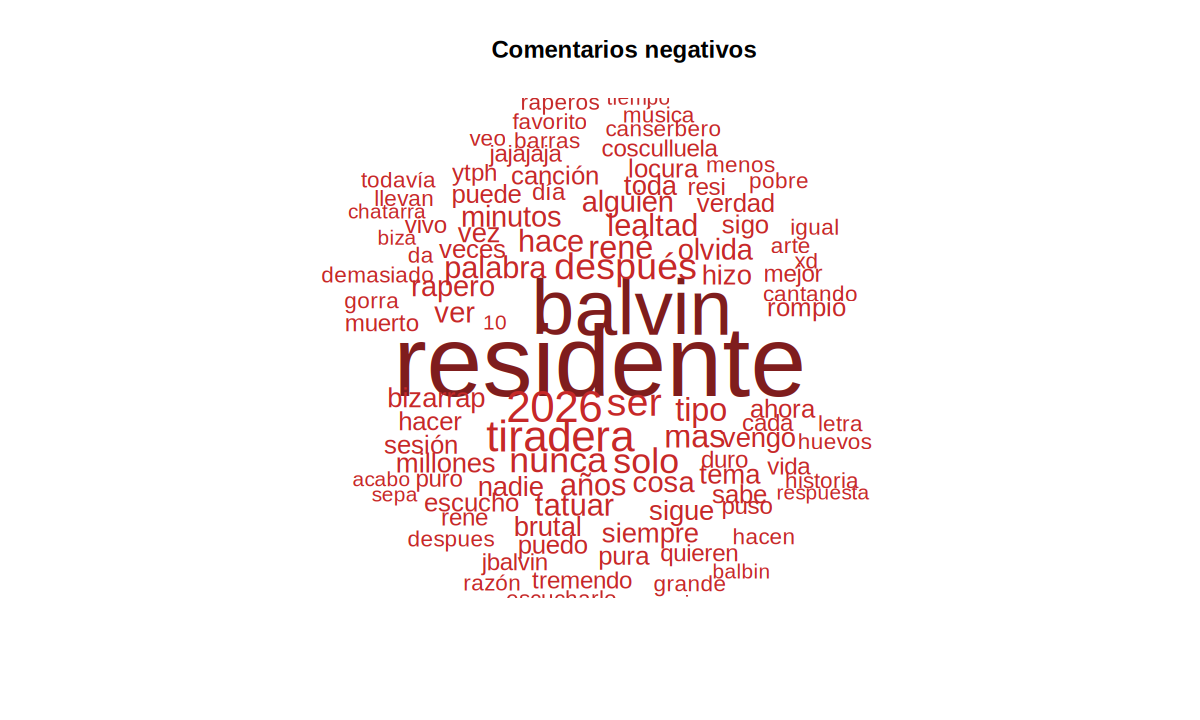

In [ ]:
palabras_vacias <- c(stopwords::stopwords("es"), stopwords::stopwords("en"), "q", "si", "xq", "pa")

nube_de_palabras <- function(tipo, colores) {
  frecuencias <- df |>
    filter(sentimiento == tipo) |>
    mutate(texto = sacar_emojis(comentario_limpio)) |>
    unnest_tokens(palabra, texto) |>
    filter(!palabra %in% palabras_vacias, nchar(palabra) > 1) |>
    count(palabra, sort = TRUE)
  wordcloud(frecuencias$palabra, frecuencias$n, max.words = 100, scale = c(5, 0.8),
            random.order = FALSE, rot.per = 0, colors = colores)
}

options(repr.plot.width = 10, repr.plot.height = 6)

nube_de_palabras("POS", c("#388e3c", "#1b5e20"))
title("Comentarios positivos")

nube_de_palabras("NEG", c("#c62828", "#7f1d1d"))
title("Comentarios negativos")

### 📅 ¿Cuándo se escribieron?

El video es de 2022, pero la gente sigue comentando. Contamos los comentarios por año.

In [ ]:
table(format(df$fecha, "%Y"))


2022 2023 2024 2025 2026 
 276    6    6    8  704 

## 💾 Guardar los resultados

Guardamos la tabla en Parquet con `arrow`, el formato por columnas de la Unidad 6: se puede abrir después con R, pandas o DuckDB sin volver a llamar a la API ni correr los modelos. El archivo aparece en el panel de archivos de Colab, desde donde se descarga.

In [ ]:
write_parquet(df, "comentarios_youtube.parquet")

dim(read_parquet("comentarios_youtube.parquet"))

[1] 1000   11

## 🔁 Otro video

Para analizar otro video, cambiar `VIDEO_ID` y volver a correr todo con **Entorno de ejecución > Ejecutar todas**.